In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


In [2]:
from analysis.calibration import build_calibration_data, calibration_curve, plot_calibration

calibration_data = build_calibration_data(horizon_days=2, wiggle_hours=48)
print(calibration_data)

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7998 resolved markets, 1900 with usable observation, 4612 dropped (no snapshot in window)
     market_id  observation_price                 observation_time  \
0      1005732             0.0015 2026-06-28 18:08:48.348515+00:00   
1      1006439             0.0035 2026-06-29 06:10:10.240657+00:00   
2      1007628             0.0015 2026-06-28 18:39:11.282601+00:00   
3      1007630             0.0015 2026-06-28 14:05:24.583246+00:00   
4      1007631             0.0045 2026-06-29 06:10:10.240789+00:00   
...        ...                ...                              ...   
1895    996332             0.0030 2026-06-28 22:19:05.079310+00:00   
1896    996333             0.0045 2026-06-29 06:10:10.240452+00:00   
1897    996334             0.0015 2026-06-27 23:55:05.866039+00:00   
1898    996811             0.0045 2026-06-29 21:57:45.591158+00:00   
1899    996893             0.0040 2026-06-29 06:10:10.216964+00:00   

      days_before_resolution  outcome     category  
0 

In [3]:
import pandas as pd
from analysis.calibration import build_calibration_data

# see what variables have most data in order to write code that we can use later. 

def sweep_horizon_wiggle(
    horizons: list[float],
    wiggles: list[float],
) -> pd.DataFrame:
    """
    Try every (horizon, wiggle) combo and report yield + quality metrics.

    Quality here = how many observations sit at a genuinely uncertain price
    (0.05 < p < 0.95) rather than already snapped to the boundary. High raw
    yield with low 'uncertain' count means you're mostly grabbing
    already-resolved markets — fine for code-testing, misleading for analysis.
    """
    results = []
    for h in horizons:
        for w in wiggles:
            df = build_calibration_data(horizon_days=h, wiggle_hours=w)
            if df.empty:
                results.append({
                    "horizon_days": h, "wiggle_hours": w,
                    "n_total": 0, "n_uncertain": 0,
                    "pct_uncertain": float("nan"),
                    "median_days_off_target": float("nan"),
                })
                continue

            uncertain = df[(df["observation_price"] > 0.05) & (df["observation_price"] < 0.95)]
            days_off = (df["days_before_resolution"] - h).abs().median()

            results.append({
                "horizon_days": h,
                "wiggle_hours": w,
                "n_total": len(df),
                "n_uncertain": len(uncertain),
                "pct_uncertain": round(100 * len(uncertain) / len(df), 1),
                "median_days_off_target": round(days_off, 3),
            })

    out = pd.DataFrame(results).sort_values(["horizon_days", "wiggle_hours"])
    return out

In [4]:
# test number of observations for different horizon/wiggle combos.

horizons = [0.5, 1, 2, 3, 5]
wiggles  = [6, 12, 24, 48]

sweep = sweep_horizon_wiggle(horizons, wiggles)
print(sweep.to_string(index=False))

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7998 resolved markets, 1398 with usable observation, 5114 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7998 resolved markets, 1528 with usable observation, 4984 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


...

[calibration] 7998 resolved markets, 1398 with usable observation, 5114 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7998 resolved markets, 1491 with usable observation, 5021 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7998 resolved markets, 1714 with usable observation, 4798 dropped (no snapshot in window)
 horizon_days  wiggle_hours  n_total  n_uncertain  pct_uncertain  median_days_off_target
          0.5             6     1398          598           42.8                   0.003
          0.5            12     1528          674           44.1                   0.003
          0.5            24     1600          686           42.9                   0.003
          0.5            48     1759          742           42.2                   0.004
          1.0             6     1457          648           44.5                   0.003
          1.0            12     1517          661           43.6                   0.003
          1.0            24     1700          759           44.6                   0.003
          1.0            48     1801          789           43.8                   0.004
          2.0             6     1518          673           44.3                   0.003
      

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7998 resolved markets, 1900 with usable observation, 4612 dropped (no snapshot in window)
          bin  mean_price  empirical_yes    n       se
(-0.001, 0.1]    0.014408       0.006809 1028 0.002565
   (0.1, 0.2]    0.145833       0.066667   90 0.026294
   (0.2, 0.3]    0.243608       0.147727   88 0.037825
   (0.3, 0.4]    0.356500       0.276596   47 0.065248
   (0.4, 0.5]    0.485240       0.351254  279 0.028579
   (0.5, 0.6]    0.530556       0.584270   89 0.052242
   (0.6, 0.7]    0.640333       0.714286   42 0.069707
   (0.7, 0.8]    0.765593       0.888889   27 0.060481
   (0.8, 0.9]    0.873865       0.976471   85 0.016441
   (0.9, 1.0]    0.975528       1.000000  125 0.000000


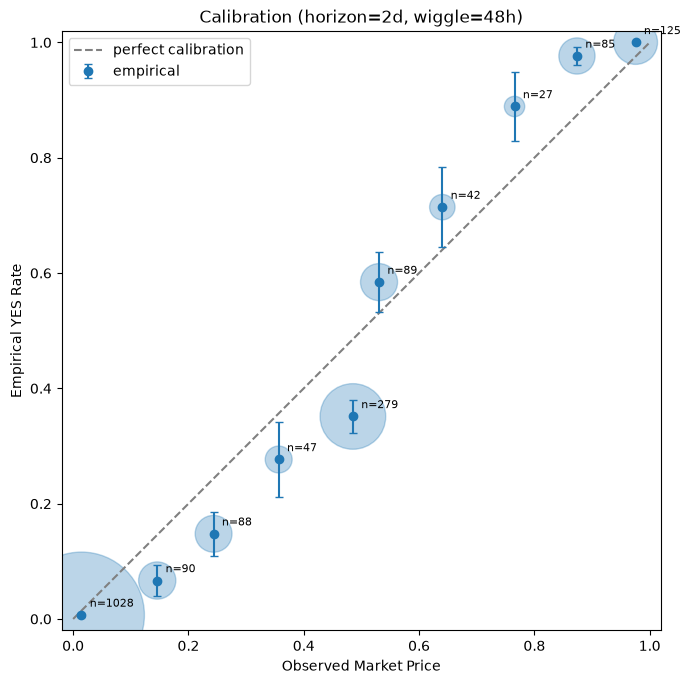

In [5]:
horizon, tol = 2, 48

calibration_data = build_calibration_data(horizon_days=horizon, wiggle_hours=tol)

curve = calibration_curve(calibration_data, n_bins=10)
print(curve[["bin", "mean_price", "empirical_yes", "n", "se"]].to_string(index=False))

plot_calibration(curve, title=f"Calibration (horizon={horizon}d, wiggle={tol}h)")

## Examine data spread

In [6]:
import pandas as pd
import numpy as np

def examine_spread(df: pd.DataFrame) -> None:
    """Print price distribution, outcome balance, boundary share, and quantiles."""
    print(f"Total usable observations: {len(df)}\n")

    print("=== OBSERVATION PRICE DISTRIBUTION ===")
    bins = [0, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]
    band = pd.cut(df["observation_price"], bins=bins, include_lowest=True)
    summary = df.groupby(band, observed=True).agg(
        n=("outcome", "size"),
        yes_rate=("outcome", "mean"),
    ).reset_index()
    print(summary.to_string(index=False))

    print("\n=== OUTCOME BALANCE ===")
    print(df["outcome"].value_counts())
    print(f"YES fraction: {df['outcome'].mean():.1%}")

    print("\n=== BOUNDARY SHARE ===")
    nb = df[(df["observation_price"] < 0.05) | (df["observation_price"] > 0.95)]
    print(f"{len(nb)} of {len(df)} obs are <0.05 or >0.95 ({len(nb)/len(df):.0%})")

    print("\n=== PRICE QUANTILES ===")
    print(df["observation_price"].describe())


## Power transform correction

In [7]:
import numpy as np
from scipy.optimize import minimize_scalar
from sklearn.model_selection import train_test_split


def power_transform(p, alpha):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return p**alpha / (p**alpha + (1 - p)**alpha)


def log_loss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def _fit_alpha(p, y):
    res = minimize_scalar(
        lambda a: log_loss(power_transform(p, a), y),
        bounds=(0.2, 5.0), method="bounded",
    )
    return res.x


def fit_transform(df: pd.DataFrame, n_boot: int = 1000, seed: int = 0):
    """
    Fit alpha on a train split, report held-out log loss, and bootstrap a
    confidence interval for alpha. alpha=1 means no correction; if the CI
    contains 1, the data is consistent with the market already being calibrated.
    """
    if len(df) < 30:
        print(f"only {len(df)} obs — too few to fit honestly")
        return None

    p = df["observation_price"].values
    y = df["outcome"].values
    p_tr, p_te, y_tr, y_te = train_test_split(p, y, test_size=0.5, random_state=seed)

    alpha = _fit_alpha(p_tr, y_tr)

    raw = log_loss(p_te, y_te)
    cor = log_loss(power_transform(p_te, alpha), y_te)

    # Bootstrap CI: refit alpha on resampled training data many times
    rng = np.random.default_rng(seed)
    n_tr = len(p_tr)
    boot_alphas = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n_tr, n_tr)        # resample with replacement
        boot_alphas[b] = _fit_alpha(p_tr[idx], y_tr[idx])

    ci_low, ci_high = np.percentile(boot_alphas, [2.5, 97.5])
    contains_one = ci_low <= 1.0 <= ci_high

    print(f"alpha = {alpha:.3f}  95% CI [{ci_low:.3f}, {ci_high:.3f}]")
    print(f"  CI {'CONTAINS 1.0 — consistent with no bias' if contains_one else 'excludes 1.0 — possible real bias'}")
    print(f"held-out log loss: raw={raw:.4f}  corrected={cor:.4f}  "
          f"{'IMPROVED' if cor < raw else 'no improvement'}")
    return {"alpha": alpha, "ci": (ci_low, ci_high), "raw": raw, "corrected": cor}

## All data

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7998 resolved markets, 1688 with usable observation, 4824 dropped (no snapshot in window)
Total usable observations: 1688

=== OBSERVATION PRICE DISTRIBUTION ===
observation_price   n  yes_rate
   (-0.001, 0.01] 613  0.000000
     (0.01, 0.05] 227  0.000000
      (0.05, 0.1]  91  0.065934
      (0.1, 0.25] 142  0.084507
      (0.25, 0.5] 319  0.307210
      (0.5, 0.75] 120  0.600000
      (0.75, 0.9]  60  0.933333
      (0.9, 0.95]  18  1.000000
     (0.95, 0.99]  48  1.000000
      (0.99, 1.0]  50  1.000000

=== OUTCOME BALANCE ===
outcome
0    1328
1     360
Name: count, dtype: int64
YES fraction: 21.3%

=== BOUNDARY SHARE ===
937 of 1688 obs are <0.05 or >0.95 (56%)

=== PRICE QUANTILES ===
count    1688.000000
mean        0.246012
std         0.310479
min         0.001500
25%         0.004500
50%         0.050500
75%         0.495000
max         0.999500
Name: observation_price, dtype: float64


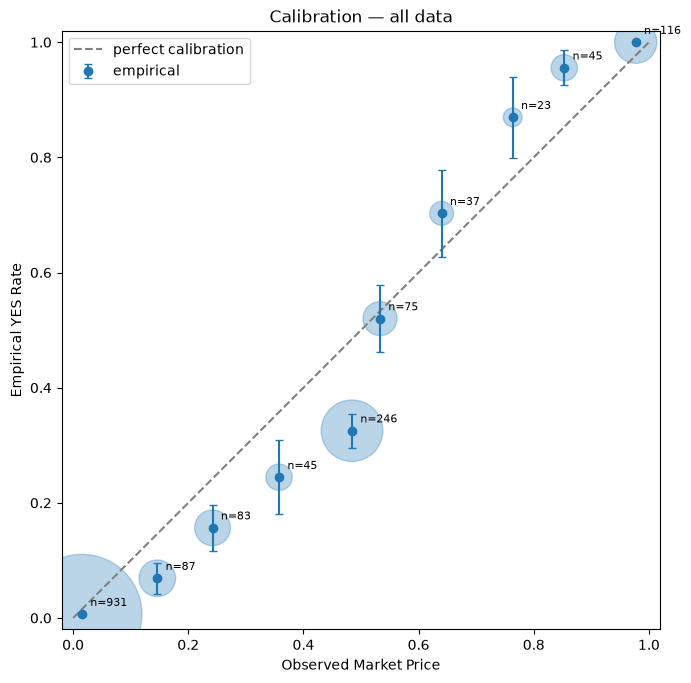

alpha = 1.370  95% CI [1.165, 1.667]
  CI excludes 1.0 — possible real bias
held-out log loss: raw=0.2210  corrected=0.2089  IMPROVED


{'alpha': np.float64(1.3695291128490799),
 'ci': (np.float64(1.1649171319933775), np.float64(1.6671224269188427)),
 'raw': np.float64(0.2209570365059329),
 'corrected': np.float64(0.20886306622252268)}

In [8]:
horizon, tol = 2, 24

calibration_data = build_calibration_data(horizon_days=horizon, wiggle_hours=tol)

examine_spread(calibration_data)

curve = calibration_curve(calibration_data, n_bins=10)
plot_calibration(curve, title="Calibration — all data")

fit_transform(calibration_data)



## Single market type
Filter the calibration data to one category. Requires `category` in the returned df (add it to get_resolved_markets).

Total usable observations: 14

=== OBSERVATION PRICE DISTRIBUTION ===
observation_price  n  yes_rate
   (-0.001, 0.01]  5       0.0
     (0.01, 0.05]  7       0.0
      (0.25, 0.5]  1       0.0
      (0.5, 0.75]  1       1.0

=== OUTCOME BALANCE ===
outcome
0    13
1     1
Name: count, dtype: int64
YES fraction: 7.1%

=== BOUNDARY SHARE ===
12 of 14 obs are <0.05 or >0.95 (86%)

=== PRICE QUANTILES ===
count    14.000000
mean      0.083536
std       0.187085
min       0.001500
25%       0.003375
50%       0.014250
75%       0.033375
max       0.665000
Name: observation_price, dtype: float64


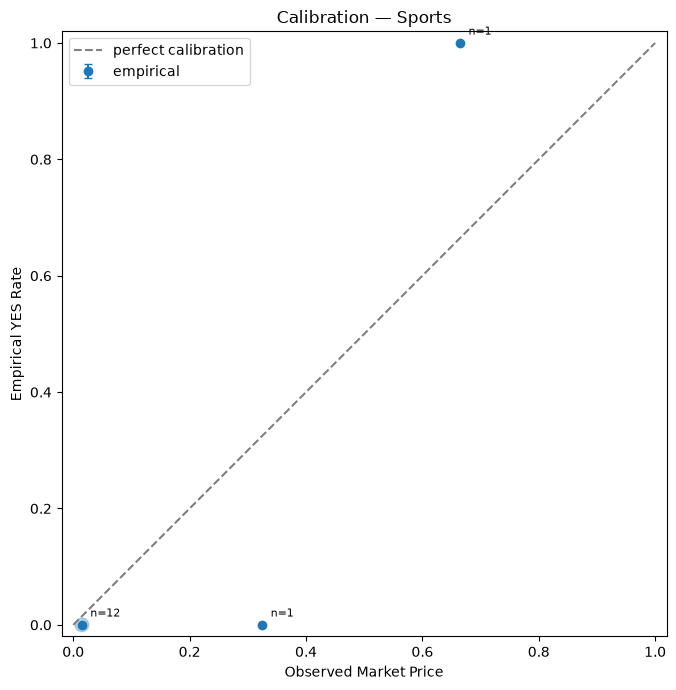

only 14 obs — too few to fit honestly


In [32]:
MARKET_TYPE = "Sports"

subset = calibration_data[calibration_data["category"] == MARKET_TYPE].copy()

examine_spread(subset)

curve = calibration_curve(subset, n_bins=10)
plot_calibration(curve, title=f"Calibration — {MARKET_TYPE}")

fit_transform(subset)

In [10]:
# Market type spread

from config import CATEGORY_PRIORITY

for i in CATEGORY_PRIORITY:
    MARKET_TYPE = i
    subset = calibration_data[calibration_data["category"] == MARKET_TYPE].copy()

    print(len(subset))
    print(i)

783
Sports
230
Politics
41
Crypto
47
Geopolitics
56
Business
71
Finance
80
Tech
0
Pop Culture
8
Science


## Compare sports vs non sports transforms on each other

In [9]:
sports = calibration_data[calibration_data["category"] == "Sports"]
non_sports = calibration_data[
    calibration_data["category"].notna() & (calibration_data["category"] != "Sports")
]
print(f"Sports: {len(sports)}  |  Non-Sports: {len(non_sports)}")
print(non_sports["category"].value_counts())

if len(non_sports) >= 40 and len(sports) >= 40:
    a_ns = _fit_alpha(non_sports["observation_price"].values, non_sports["outcome"].values)
    raw = log_loss(sports["observation_price"].values, sports["outcome"].values)
    cor = log_loss(power_transform(sports["observation_price"].values, a_ns), sports["outcome"].values)
    print(f"\nfit Non-Sports (alpha={a_ns:.3f}) -> Sports: "
          f"raw={raw:.4f} cor={cor:.4f} {'HOLDS' if cor<raw else 'FAILS'}")

    a_s = _fit_alpha(sports["observation_price"].values, sports["outcome"].values)
    raw2 = log_loss(non_sports["observation_price"].values, non_sports["outcome"].values)
    cor2 = log_loss(power_transform(non_sports["observation_price"].values, a_s), non_sports["outcome"].values)
    print(f"fit Sports (alpha={a_s:.3f}) -> Non-Sports: "
          f"raw2={raw2:.4f} cor2={cor2:.4f} {'HOLDS' if cor2<raw2 else 'FAILS'}")

Sports: 783  |  Non-Sports: 651
category
Politics       230
Other          118
Tech            80
Finance         71
Business        56
Geopolitics     47
Crypto          41
Science          8
Name: count, dtype: int64

fit Non-Sports (alpha=1.752) -> Sports: raw=0.3316 cor=0.3145 HOLDS
fit Sports (alpha=1.829) -> Non-Sports: raw2=0.0511 cor2=0.0404 HOLDS


## Horizon Sensitivty

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def horizon_sensitivity(horizons_days: list[float], wiggle_hours: float = 24, n_boot: int = 500):
    """
    Fit the calibration correction at several observation horizons and track
    how alpha (and its uncertainty) changes with distance-to-resolution.

    Returns a DataFrame; also plots alpha vs horizon with bootstrap CIs.
    """
    rows = []
    for h in horizons_days:
        data = build_calibration_data(horizon_days=h, wiggle_hours=wiggle_hours)
        n = len(data)
        if n < 40:
            rows.append({"horizon": h, "n": n, "alpha": np.nan,
                         "ci_low": np.nan, "ci_high": np.nan,
                         "raw_ll": np.nan, "cor_ll": np.nan})
            continue

        p = data["observation_price"].values
        y = data["outcome"].values

        alpha = _fit_alpha(p, y)

        # bootstrap CI on alpha
        rng = np.random.default_rng(0)
        boot = np.array([
            _fit_alpha(*(lambda idx: (p[idx], y[idx]))(rng.integers(0, n, n)))
            for _ in range(n_boot)
        ])
        ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

        # in-sample log loss raw vs corrected (descriptive, not the edge test)
        raw_ll = log_loss(p, y)
        cor_ll = log_loss(power_transform(p, alpha), y)

        rows.append({"horizon": h, "n": n, "alpha": alpha,
                     "ci_low": ci_low, "ci_high": ci_high,
                     "raw_ll": raw_ll, "cor_ll": cor_ll})

    df = pd.DataFrame(rows)
    print(df.to_string(index=False))

    # Plot alpha vs horizon with CI band
    valid = df.dropna(subset=["alpha"])
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(valid["horizon"], valid["alpha"], "o-", color="C0", label="fitted alpha")
    ax.fill_between(valid["horizon"], valid["ci_low"], valid["ci_high"],
                    alpha=0.2, color="C0", label="95% bootstrap CI")
    ax.axhline(1.0, color="gray", linestyle="--", label="no bias (alpha=1)")
    ax.set_xlabel("Observation horizon (days before resolution)")
    ax.set_ylabel("Fitted alpha")
    ax.set_title("Favorite-longshot bias vs. observation horizon")
    ax.legend()
    # annotate sample sizes
    for _, r in valid.iterrows():
        ax.annotate(f"n={int(r['n'])}", (r["horizon"], r["alpha"]),
                    textcoords="offset points", xytext=(0, 10), fontsize=8, ha="center")
    plt.tight_layout()
    plt.show()

    return df

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7999 resolved markets, 1601 with usable observation, 4912 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7999 resolved markets, 1701 with usable observation, 4812 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


...

[calibration] 7999 resolved markets, 1492 with usable observation, 5021 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7999 resolved markets, 1513 with usable observation, 5000 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 7999 resolved markets, 1096 with usable observation, 5417 dropped (no snapshot in window)
 horizon    n    alpha   ci_low  ci_high   raw_ll   cor_ll
     0.5 1601 1.677182 1.459219 1.998084 0.197016 0.182745
     1.0 1701 1.720241 1.521423 2.061812 0.203932 0.188096
     2.0 1689 1.512735 1.336357 1.763444 0.226769 0.217213
     3.0 1667 1.439123 1.261988 1.664689 0.230792 0.223349
     5.0 1492 1.413497 1.216011 1.675395 0.222446 0.215949
     7.0 1513 1.346032 1.181513 1.633229 0.218913 0.213740
    14.0 1096 1.247643 1.101742 1.483316 0.248470 0.245312


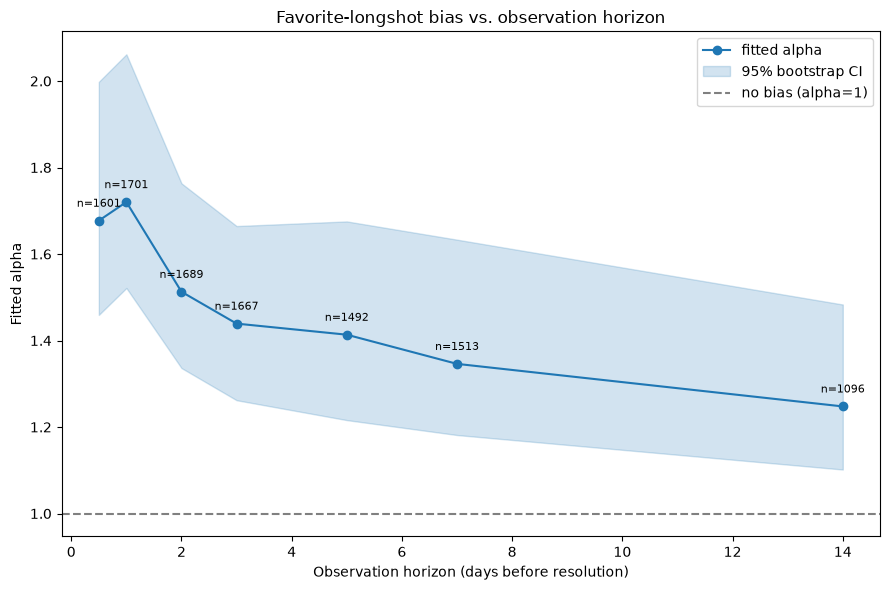

,horizon,n,alpha,ci_low,ci_high,raw_ll,cor_ll
0,0.5,1601,1.677182,1.459219,1.998084,0.197016,0.182745
1,1.0,1701,1.720241,1.521423,2.061812,0.203932,0.188096
2,2.0,1689,1.512735,1.336357,1.763444,0.226769,0.217213
3,3.0,1667,1.439123,1.261988,1.664689,0.230792,0.223349
4,5.0,1492,1.413497,1.216011,1.675395,0.222446,0.215949
5,7.0,1513,1.346032,1.181513,1.633229,0.218913,0.213740
6,14.0,1096,1.247643,1.101742,1.483316,0.248470,0.245312


In [12]:
horizon_sensitivity(horizons_days=[0.5, 1, 2, 3, 5, 7, 14], wiggle_hours=24)